# T17. Meteorología frente a demanda y días anómalos

**Objetivo.** Ver si la lluvia, la temperatura y el viento explican los días con pocos viajes y el crecimiento de la demanda a lo largo del mes.

**Valor para el proyecto.** Decide si se excluye algún día del análisis y si la semana reservada es comparable con el periodo de ajuste. Si la demanda crece por algo que no es el tiempo, la validación temporal es más exigente y hay que decirlo.

Datos de la API histórica de Open-Meteo para Roma centro (lat 41,8967, lon 12,4822), guardados en `datos/externos/meteorologia/` con sus metadatos (fuente, modelo `best_match` con ECMWF IFS, ERA5 y ERA5-Land, y licencia CC BY 4.0). Solo se descarga si no hay respuesta guardada o con `DESCARGAR = True`. Viajes elegibles del mes completo; con 28 días, las asociaciones son orientativas.

In [1]:
import hashlib
import json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.dates import DateFormatter
from matplotlib.patches import Patch
from scipy.stats import spearmanr

from comun.config import cargar_config, carpeta_tablas, ruta
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
ZONA = CFG["datos"]["zona_horaria"]
INICIO = CFG["datos"]["periodos"]["ajuste"][0]
FIN = CFG["datos"]["periodos"]["reservada"][1]

# Poner a True para volver a descargar los datos de Open-Meteo. Si es False, solo se
# descarga cuando no hay ninguna respuesta guardada; si no, se trabaja sin conexión.
DESCARGAR = False

PARAMETROS = {
    "url": "https://archive-api.open-meteo.com/v1/archive",
    # Roma centro.
    "latitud": 41.8967,
    "longitud": 12.4822,
    "diarias": ["precipitation_sum", "rain_sum", "temperature_2m_mean", "temperature_2m_max",
                "temperature_2m_min", "wind_speed_10m_max", "wind_gusts_10m_max"],
    # Viento medio y racha a 10 m en el instante de cada hora (apartado 6).
    "horarias": ["precipitation", "temperature_2m", "wind_speed_10m", "wind_gusts_10m"],
    # Hora con lluvia: más de 0,1 mm en la hora.
    "umbral_lluvia_mm": 0.1,
    # Para el cociente horario, las horas sin lluvia de referencia son las de la misma hora y
    # tipo de día a menos de esta distancia en días (limita el efecto de la tendencia).
    "ventana_referencia_dias": 7,
    # Horas del día en las que se compara (fuera de ellas casi no hay viajes).
    "horas_comparacion": [7, 23],
    # Día anómalo: por debajo de esta fracción de la mediana de su tipo de día (mes completo).
    "fraccion_anomalo": 0.70,
    "dias_a_explicar": ["2021-02-07"],
    # Apartado 6: hora ventosa con viento medio de al menos 20 km/h (percentil 90 de las horas de
    # 7 a 23 h); su referencia son horas secas en calma, por debajo de 10 km/h (cerca de la mediana).
    "umbral_viento_kmh": 20,
    "umbral_calma_kmh": 10,
}

METADATOS_FUENTE = {
    "fuente": "Open-Meteo, Historical Weather API (https://open-meteo.com/en/docs/historical-weather-api)",
    "modelo": ("models=best_match (valor por defecto). Según la documentación, combina ECMWF IFS HRES "
               "(9 km, desde 2017), ERA5 (0,25°) y ERA5-Land (0,1°)."),
    "licencia": "CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/)",
    "atribucion": "Weather data by Open-Meteo.com (https://open-meteo.com/)",
    "citas": [
        "Zippenfenig, P. (2023). Open-Meteo.com Weather API [Computer software]. Zenodo. "
        "https://doi.org/10.5281/ZENODO.7970649",
        "Hersbach, H. et al. (2023). ERA5 hourly data on single levels from 1940 to present. ECMWF. "
        "https://doi.org/10.24381/cds.adbb2d47",
    ],
    "nota_copernicus": "Generated using Copernicus Climate Change Service information.",
    "convencion_horaria": ("Horas locales Europe/Rome. 'precipitation' es la suma de la hora anterior a la "
                           "marca de tiempo."),
}

# Variables diarias de la API con la unidad en el nombre (mm, °C, km/h).
NOMBRES_DIARIAS = {"precipitation_sum": "precipitacion_mm", "rain_sum": "lluvia_mm",
                   "temperature_2m_mean": "temp_media_c", "temperature_2m_max": "temp_max_c",
                   "temperature_2m_min": "temp_min_c", "wind_speed_10m_max": "viento_max_kmh",
                   "wind_gusts_10m_max": "racha_max_kmh"}
DIAS_SEMANA = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
COLORES_TIPO = {"laborable": AZUL, "fin_de_semana": NARANJA}
NOMBRES_TIPO = {"laborable": "Laborable", "fin_de_semana": "Fin de semana"}


def guardar_tabla(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", index=False, lineterminator="\n")


def tabla_resumen(resumen):
    valores = [round(float(x), 4) if isinstance(x, (float, np.floating)) else
               (int(x) if isinstance(x, (int, np.integer)) else x) for x in resumen.values()]
    return pd.DataFrame({"indicador": list(resumen), "valor": pd.Series(valores, dtype=object)})


def carpeta_meteo():
    carpeta = ruta("externos") / "meteorologia"
    carpeta.mkdir(parents=True, exist_ok=True)
    return carpeta


def descargar():
    """Descarga la respuesta de Open-Meteo y la guarda tal cual con sus metadatos."""
    import requests

    p = PARAMETROS
    consulta = {"latitude": p["latitud"], "longitude": p["longitud"], "start_date": INICIO, "end_date": FIN,
                "daily": ",".join(p["diarias"]), "hourly": ",".join(p["horarias"]), "timezone": ZONA}
    respuesta = requests.get(p["url"], params=consulta, timeout=60)
    respuesta.raise_for_status()
    datos = respuesta.json()
    if "error" in datos or "daily" not in datos or "hourly" not in datos:
        raise RuntimeError(f"Respuesta inesperada de Open-Meteo: {respuesta.text[:300]}")
    ahora = datetime.now(timezone.utc)
    destino = carpeta_meteo() / f"open-meteo_roma_2021-02_{ahora:%Y-%m-%d}.json"
    destino.write_bytes(respuesta.content)
    meta = {
        "url": p["url"], "url_completa": respuesta.url, "parametros": consulta,
        "fecha_descarga_utc": ahora.isoformat(timespec="seconds"), **METADATOS_FUENTE,
        "unidades_diarias": datos.get("daily_units"), "unidades_horarias": datos.get("hourly_units"),
        "coordenadas_celda": {"latitude": datos.get("latitude"), "longitude": datos.get("longitude"),
                              "elevation": datos.get("elevation")},
        "sha256": hashlib.sha256(respuesta.content).hexdigest(),
    }
    destino.with_name(destino.stem + ".meta.json").write_text(
        json.dumps(meta, ensure_ascii=False, indent=2) + "\n", encoding="utf-8", newline="\n")
    return destino


def tiene_variables(fichero):
    """Una respuesta guardada sirve si trae todas las variables que piden los PARAMETROS."""
    d = json.loads(fichero.read_text(encoding="utf-8"))
    return (set(PARAMETROS["diarias"]) <= set(d.get("daily", {}))
            and set(PARAMETROS["horarias"]) <= set(d.get("hourly", {})))


guardadas = sorted(f for f in carpeta_meteo().glob("open-meteo_roma_2021-02_*.json")
                   if not f.name.endswith(".meta.json") and tiene_variables(f))
FICHERO = descargar() if (DESCARGAR or not guardadas) else guardadas[-1]
datos_meteo = json.loads(FICHERO.read_text(encoding="utf-8"))
diario = pd.DataFrame(datos_meteo["daily"]).rename(columns={"time": "fecha", **NOMBRES_DIARIAS})
diario["fecha"] = diario["fecha"].astype("string")
horario = pd.DataFrame(datos_meteo["hourly"])
horario["inicio"] = pd.to_datetime(horario["time"]).dt.tz_localize(ZONA)
# 'precipitation' se refiere a la hora anterior a la marca: la lluvia del intervalo
# [h, h + 1) es la de la marca h + 1.
horario["precipitacion_mm"] = horario["precipitation"].shift(-1)
horario["temperatura_c"] = horario["temperature_2m"]
# El viento es instantáneo: se toma el de la marca h como el del intervalo [h, h + 1).
horario["viento_kmh"] = horario["wind_speed_10m"]
horario["racha_kmh"] = horario["wind_gusts_10m"]
horario = horario[["inicio", "precipitacion_mm", "temperatura_c", "viento_kmh", "racha_kmh"]]
assert len(diario) == len(pd.date_range(INICIO, FIN)), len(diario)

viajes = cargar_viajes()
print(f"Meteorología: {FICHERO.name}. {len(viajes)} viajes elegibles en el mes")

Meteorología: open-meteo_roma_2021-02_2026-11-18.json. 23292 viajes elegibles en el mes


## 1. Viajes diarios y lluvia

**Qué queremos ver.** Los viajes de cada día del mes, separados en laborables y fines de semana, junto a la lluvia diaria y la tendencia del periodo de ajuste.

**Por qué importa.** Si los días con pocos viajes coinciden con la lluvia, son días reales de baja demanda y no errores; si el crecimiento no sigue al tiempo, hay otra causa.

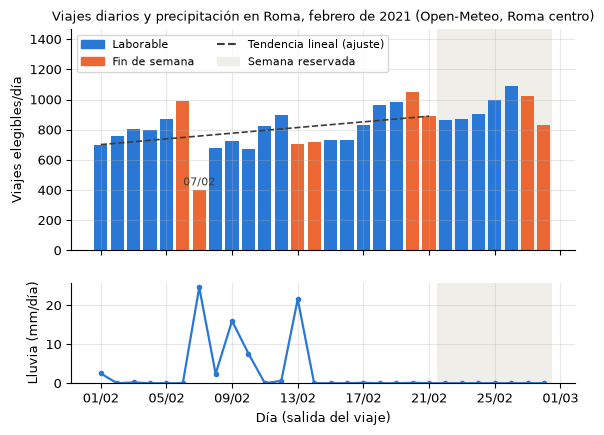

,fecha,dia_semana,viajes,precipitacion_mm,horas_lluvia,temp_media_c
0,2021-02-01,lunes,697,2.5,3,8.9
1,2021-02-02,martes,756,0.0,0,9.9
2,2021-02-03,miércoles,805,0.2,0,11.0
3,2021-02-04,jueves,797,0.0,0,13.0
4,2021-02-05,viernes,872,0.0,0,11.5
5,2021-02-06,sábado,990,0.0,0,13.6
6,2021-02-07,domingo,403,24.6,21,13.5
7,2021-02-08,lunes,678,2.4,5,11.3
8,2021-02-09,martes,722,16.0,11,12.2
9,2021-02-10,miércoles,670,7.6,12,12.5


In [2]:
fechas = pd.date_range(INICIO, FIN, freq="D")
serie = pd.DataFrame({"fecha": pd.Index(fechas.strftime("%Y-%m-%d"), dtype="string")})
serie["dia_semana"] = [DIAS_SEMANA[d] for d in fechas.day_of_week]
serie["tipo_dia"] = np.where(fechas.day_of_week >= 5, "fin_de_semana", "laborable")
serie["periodo"] = np.where(serie["fecha"] <= CFG["datos"]["periodos"]["ajuste"][1], "ajuste", "reservada")
serie["viajes"] = (viajes["tsO"].dt.strftime("%Y-%m-%d").value_counts().reindex(serie["fecha"], fill_value=0)
                   .to_numpy())
horas_lluvia = (horario.assign(fecha=horario["inicio"].dt.strftime("%Y-%m-%d"),
                               lluvia=horario["precipitacion_mm"] > PARAMETROS["umbral_lluvia_mm"])
                .groupby("fecha")["lluvia"].sum())
serie["horas_lluvia"] = horas_lluvia.reindex(serie["fecha"], fill_value=0).to_numpy().astype(int)
serie = serie.merge(diario, on="fecha", how="left")
# Día anómalo: por debajo del 70 % de la mediana de su tipo de día en el mes.
medianas = serie.groupby("tipo_dia")["viajes"].median()
serie["mediana_tipo_dia"] = serie["tipo_dia"].map(medianas)
serie["pct_mediana_tipo_dia"] = (100 * serie["viajes"] / serie["mediana_tipo_dia"]).round(1)
serie["anomalo"] = serie["viajes"] < PARAMETROS["fraccion_anomalo"] * serie["mediana_tipo_dia"]
guardar_tabla(serie, "T17_serie_diaria")

x = pd.to_datetime(serie["fecha"])
en_ajuste = serie["periodo"] == "ajuste"
idx = np.arange(len(serie))[en_ajuste]
pendiente, ordenada = np.polyfit(idx, serie.loc[en_ajuste, "viajes"].to_numpy(dtype=float), 1)
fig, (eje1, eje2) = plt.subplots(2, 1, figsize=(6.5, 4.6), sharex=True, height_ratios=[2.2, 1])
for eje in (eje1, eje2):
    reservada = x[~en_ajuste]
    eje.axvspan(reservada.min() - pd.Timedelta(hours=12), reservada.max() + pd.Timedelta(hours=12),
                color="#efeee9", zorder=0, lw=0)
eje1.bar(x, serie["viajes"], color=[COLORES_TIPO[c] for c in serie["tipo_dia"]], width=0.8)
eje1.plot(x[en_ajuste], ordenada + pendiente * idx, color="#3d3c39", lw=1.2, ls="--")
for _, fila in serie[serie["anomalo"] | serie["fecha"].isin(PARAMETROS["dias_a_explicar"])].iterrows():
    eje1.annotate(pd.Timestamp(fila["fecha"]).strftime("%d/%m"), (pd.Timestamp(fila["fecha"]), fila["viajes"]),
                  xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color="#3d3c39")
eje1.legend(handles=[Patch(color=AZUL, label="Laborable"), Patch(color=NARANJA, label="Fin de semana"),
                     plt.Line2D([], [], color="#3d3c39", ls="--", label="Tendencia lineal (ajuste)"),
                     Patch(color="#efeee9", label="Semana reservada")], loc="upper left", ncol=2)
eje1.set_ylim(0, serie["viajes"].max() * 1.35)
eje1.set_ylabel("Viajes elegibles/día")
eje2.plot(x, serie["precipitacion_mm"], color=AZUL, lw=1.6, marker="o", ms=3)
eje2.set_ylabel("Lluvia (mm/día)")
eje2.set_ylim(0, None)
eje2.xaxis.set_major_formatter(DateFormatter("%d/%m"))
eje2.set_xlabel("Día (salida del viaje)")
eje1.set_title("Viajes diarios y precipitación en Roma, febrero de 2021 (Open-Meteo, Roma centro)", fontsize=9)
guardar_figura(fig, TEMA, "T17_viajes_lluvia")

exportar(FASE, "t17_serie", {"dias": serie, "tendencia_ajuste": {"ordenada": ordenada, "pendiente": pendiente}})
display(serie[["fecha", "dia_semana", "viajes", "precipitacion_mm", "horas_lluvia", "temp_media_c"]].head(14))

**Conclusiones.**

- La lluvia se concentra en la primera mitad del mes: 75,7 mm en el ajuste, con 6 días de más de 1 mm, y ninguna en la semana reservada.
- El día con menos viajes, el domingo 07/02, es el de más lluvia (24,6 mm). Los otros días con más de 5 mm (09/02, 10/02 y 13/02) también quedan por debajo de la tendencia.

## 2. Correlación de los viajes diarios con el tiempo

**Qué queremos ver.** La correlación de Spearman entre los viajes diarios y la lluvia, la temperatura media, las horas de lluvia y el viento máximo, en todo el mes y por tipo de día.

**Por qué importa.** Mide la asociación sin suponer una relación lineal. Con 28 días, y solo 8 de fin de semana, es una indicación, no una prueba.

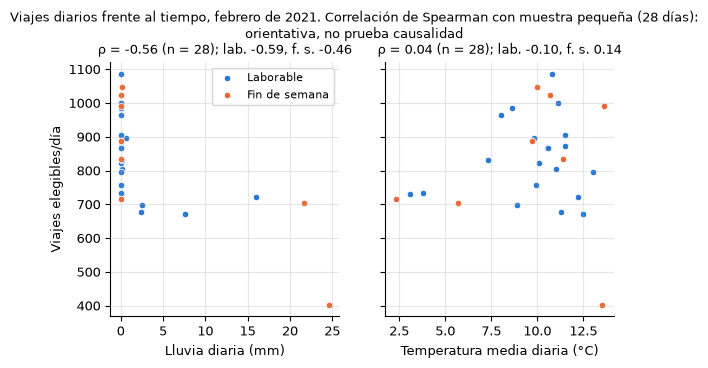

grupo,fin_de_semana,laborable,todos
variable,,,
horas_lluvia,-0.764,-0.585,-0.636
precipitacion_mm,-0.464,-0.589,-0.563
temp_media_c,0.143,-0.099,0.037
viento_max_kmh,-0.881,-0.296,-0.490


In [3]:
filas = []
for variable in ["precipitacion_mm", "temp_media_c", "horas_lluvia", "viento_max_kmh"]:
    for grupo, sub in [("todos", serie), ("laborable", serie[serie["tipo_dia"] == "laborable"]),
                       ("fin_de_semana", serie[serie["tipo_dia"] == "fin_de_semana"])]:
        r = spearmanr(sub[variable], sub["viajes"])
        filas.append({"variable": variable, "grupo": grupo, "n": len(sub),
                      "spearman_rho": round(float(r.statistic), 3), "p_valor": round(float(r.pvalue), 4)})
correlaciones = pd.DataFrame(filas)
guardar_tabla(correlaciones, "T17_correlaciones")

fig, ejes = plt.subplots(1, 2, figsize=(6.5, 3.3), sharey=True)
for eje, (variable, etiqueta) in zip(ejes, [("precipitacion_mm", "Lluvia diaria (mm)"),
                                            ("temp_media_c", "Temperatura media diaria (°C)")]):
    for tipo, color in COLORES_TIPO.items():
        sub = serie[serie["tipo_dia"] == tipo]
        eje.scatter(sub[variable], sub["viajes"], s=22, color=color, edgecolor="white", lw=0.6,
                    label=NOMBRES_TIPO[tipo])
    r = correlaciones[correlaciones["variable"] == variable].set_index("grupo")
    eje.set_title(f"ρ = {r.loc['todos', 'spearman_rho']:.2f} (n = {r.loc['todos', 'n']}); "
                  f"lab. {r.loc['laborable', 'spearman_rho']:.2f}, f. s. {r.loc['fin_de_semana', 'spearman_rho']:.2f}",
                  fontsize=9)
    eje.set_xlabel(etiqueta)
ejes[0].set_ylabel("Viajes elegibles/día")
ejes[0].legend(loc="upper right")
fig.suptitle("Viajes diarios frente al tiempo, febrero de 2021. Correlación de Spearman con muestra pequeña "
             "(28 días):\norientativa, no prueba causalidad", fontsize=9, y=1.04)
guardar_figura(fig, TEMA, "T17_dispersion")

exportar(FASE, "t17_correlaciones", correlaciones)
display(correlaciones.pivot(index="variable", columns="grupo", values="spearman_rho"))

**Conclusiones.**

- Los viajes bajan con la lluvia: Spearman de −0,56 con la lluvia diaria y de −0,64 con las horas de lluvia (n = 28). En laborables es −0,59 (n = 20).
- La temperatura media no se asocia con los viajes (0,04): en febrero de 2021 varió poco y no explica la demanda.

## 3. Viajes en las horas con lluvia

**Qué queremos ver.** Los viajes de cada hora con más de 0,1 mm de lluvia frente a los de la misma hora y tipo de día sin lluvia en los 7 días de alrededor, de 7 a 23 h.

**Por qué importa.** Mide el efecto de la lluvia hora a hora, con una referencia cercana en el tiempo para no confundirlo con el crecimiento del mes.

In [4]:
p = PARAMETROS
h = horario.dropna(subset=["precipitacion_mm"]).copy()
h["viajes"] = viajes["tsO"].dt.floor("h").value_counts().reindex(h["inicio"], fill_value=0).to_numpy()
h["fecha"] = h["inicio"].dt.tz_localize(None).dt.normalize()
h["hora"] = h["inicio"].dt.hour
h["tipo_dia"] = np.where(h["inicio"].dt.day_of_week >= 5, "fin_de_semana", "laborable")
h["lluvia"] = h["precipitacion_mm"] > p["umbral_lluvia_mm"]
h0, h1 = p["horas_comparacion"]
h = h[h["hora"].between(h0, h1 - 1)]

secas = h[~h["lluvia"]]
filas = []
for _, fila in h[h["lluvia"]].iterrows():
    ref = secas[(secas["hora"] == fila["hora"]) & (secas["tipo_dia"] == fila["tipo_dia"])
                & ((secas["fecha"] - fila["fecha"]).abs() <= pd.Timedelta(days=p["ventana_referencia_dias"]))]
    filas.append({"fecha": fila["fecha"].strftime("%Y-%m-%d"), "hora": int(fila["hora"]),
                  "tipo_dia": fila["tipo_dia"], "precipitacion_mm": round(float(fila["precipitacion_mm"]), 2),
                  "viajes": int(fila["viajes"]), "horas_referencia": len(ref),
                  "viajes_esperados": round(float(ref["viajes"].mean()), 3) if len(ref) else np.nan})
horas = pd.DataFrame(filas)
horas["cociente"] = (horas["viajes"] / horas["viajes_esperados"]).round(3)
guardar_tabla(horas, "T17_lluvia_horaria")

validas = horas.dropna(subset=["viajes_esperados"])
filas = []
for grupo, sub in [("todos", validas), ("laborable", validas[validas["tipo_dia"] == "laborable"]),
                   ("fin_de_semana", validas[validas["tipo_dia"] == "fin_de_semana"])]:
    filas.append({"grupo": grupo, "horas_lluvia": len(sub), "viajes": int(sub["viajes"].sum()),
                  "viajes_esperados": round(float(sub["viajes_esperados"].sum()), 1),
                  "cociente_agregado": round(float(sub["viajes"].sum() / sub["viajes_esperados"].sum()), 3)
                  if len(sub) else np.nan,
                  "cociente_mediana": round(float(sub["cociente"].median()), 3) if len(sub) else np.nan})
lluvia_horaria = pd.DataFrame(filas)
guardar_tabla(lluvia_horaria, "T17_lluvia_horaria_resumen")

exportar(FASE, "t17_lluvia_horaria", {"horas": horas, "resumen": lluvia_horaria})
display(lluvia_horaria)

,grupo,horas_lluvia,viajes,viajes_esperados,cociente_agregado,cociente_mediana
0,todos,42,1277,1842.9,0.693,0.677
1,laborable,22,849,962.3,0.882,0.903
2,fin_de_semana,20,428,880.7,0.486,0.431


**Conclusiones.**

- En las 42 horas con lluvia hubo el 69 % de los viajes esperados: el 88 % en laborables y solo el 49 % en fin de semana.
- La lluvia reduce mucho más los viajes del fin de semana que los de los laborables, en los que la mayoría se mantiene.

## 4. Días anómalos

**Qué queremos ver.** El 07/02 y cualquier otro día por debajo del 70 % de la mediana de su tipo de día, con su lluvia, temperatura y viento.

**Por qué importa.** Decide si algún día se quita del análisis o se trata aparte en el simulador.

In [5]:
columnas = ["fecha", "dia_semana", "tipo_dia", "periodo", "viajes", "mediana_tipo_dia", "pct_mediana_tipo_dia",
            "anomalo", "precipitacion_mm", "lluvia_mm", "horas_lluvia", "temp_media_c", "temp_max_c",
            "viento_max_kmh"]
anomalos = serie.loc[serie["anomalo"] | serie["fecha"].isin(PARAMETROS["dias_a_explicar"]), columnas]
guardar_tabla(anomalos, "T17_dias_anomalos")
exportar(FASE, "t17_dias_anomalos", anomalos)
display(anomalos)

,fecha,dia_semana,tipo_dia,periodo,viajes,mediana_tipo_dia,pct_mediana_tipo_dia,anomalo,precipitacion_mm,lluvia_mm,horas_lluvia,temp_media_c,temp_max_c,viento_max_kmh
6,2021-02-07,domingo,fin_de_semana,ajuste,403,861.5,46.8,True,24.6,24.6,21,13.5,16.8,29.6


**Conclusiones.**

- Solo el **07/02** está por debajo del 70 %: 403 viajes, el 46,8 % de la mediana de los fines de semana, con 24,6 mm y 21 horas de lluvia.
- Es demanda real de un día de lluvia: no se excluye, pero no debe usarse como día de diseño ni como día tipo.

## 5. Tendencia y semana reservada

**Qué queremos ver.** La pendiente de los viajes diarios en el ajuste, cuánto cambia al tener en cuenta el fin de semana, la lluvia y la temperatura, y el cociente entre la semana reservada y el ajuste para cada día de la semana.

**Por qué importa.** Si el tiempo explicara el crecimiento, la semana reservada sería comparable con el ajuste una vez descontado. Si no, la validación con la reservada es más exigente.

In [6]:
def ols(y, columnas):
    """Mínimos cuadrados con constante: coeficientes, errores típicos y R²."""
    X = np.column_stack([np.ones(len(y))] + list(columnas.values()))
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    residuos = y - X @ beta
    sigma2 = residuos @ residuos / (len(y) - X.shape[1])
    ee = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    salida = {"r2": 1 - residuos @ residuos / ((y - y.mean()) @ (y - y.mean()))}
    for i, nombre in enumerate(["constante"] + list(columnas)):
        salida[f"coef_{nombre}"] = beta[i]
        salida[f"ee_{nombre}"] = ee[i]
    return salida


s = serie.assign(indice_dia=np.arange(len(serie), dtype=float),
                 fin_de_semana=(serie["tipo_dia"] == "fin_de_semana").astype(float))
s_aj = s[s["periodo"] == "ajuste"]
filas = []
for nombre, periodo, sub, columnas in [
    ("tendencia", "ajuste", s_aj, ["indice_dia"]),
    ("tendencia + fin_de_semana", "ajuste", s_aj, ["indice_dia", "fin_de_semana"]),
    ("tendencia + fin_de_semana", "mes", s, ["indice_dia", "fin_de_semana"]),
    ("tendencia + fin_de_semana + lluvia + temperatura", "mes", s,
     ["indice_dia", "fin_de_semana", "precipitacion_mm", "temp_media_c"]),
]:
    r = ols(sub["viajes"].to_numpy(dtype=float), {c: sub[c].to_numpy(dtype=float) for c in columnas})
    filas.append({"modelo": nombre, "periodo": periodo, "n": len(sub),
                  "pendiente_viajes_dia_por_dia": r["coef_indice_dia"], "pendiente_ee": r["ee_indice_dia"],
                  "pendiente_pct_media_por_semana": 100 * 7 * r["coef_indice_dia"] / sub["viajes"].mean(),
                  "coef_fin_de_semana": r.get("coef_fin_de_semana", np.nan),
                  "coef_lluvia_viajes_por_mm": r.get("coef_precipitacion_mm", np.nan),
                  "ee_lluvia": r.get("ee_precipitacion_mm", np.nan),
                  "coef_temperatura_viajes_por_c": r.get("coef_temp_media_c", np.nan),
                  "ee_temperatura": r.get("ee_temp_media_c", np.nan),
                  "r2": r["r2"]})
tendencia = pd.DataFrame(filas)
numericas = tendencia.columns.drop(["modelo", "periodo", "n"])
tendencia[numericas] = tendencia[numericas].astype(float).round(3)
guardar_tabla(tendencia, "T17_tendencia")

medias = serie.groupby(["dia_semana", "periodo"])["viajes"].mean().unstack("periodo").reindex(DIAS_SEMANA)
semana = pd.DataFrame({"dia_semana": medias.index,
                       "viajes_media_ajuste": medias["ajuste"].round(2).to_numpy(),
                       "viajes_reservada": medias["reservada"].round(2).to_numpy()})
total = pd.DataFrame([{"dia_semana": "semana", "viajes_media_ajuste": round(medias["ajuste"].mean(), 2),
                       "viajes_reservada": round(medias["reservada"].mean(), 2)}])
semana = pd.concat([semana, total], ignore_index=True)
semana["cociente_reservada_ajuste"] = (semana["viajes_reservada"] / semana["viajes_media_ajuste"]).round(3)
guardar_tabla(semana, "T17_cociente_semana")

exportar(FASE, "t17_tendencia", {"modelos": tendencia, "semana": semana})
display(tendencia[["modelo", "periodo", "n", "pendiente_viajes_dia_por_dia", "pendiente_ee", "r2"]], semana)

,modelo,periodo,n,pendiente_viajes_dia_por_dia,pendiente_ee,r2
0,tendencia,ajuste,21,9.416,4.876,0.164
1,tendencia + fin_de_semana,ajuste,21,10.223,5.138,0.181
2,tendencia + fin_de_semana,mes,28,10.495,2.969,0.334
3,tendencia + fin_de_semana + lluvia + temperatura,mes,28,7.514,2.446,0.636


,dia_semana,viajes_media_ajuste,viajes_reservada,cociente_reservada_ajuste
0,lunes,702.00,866.00,1.234
1,martes,737.00,868.00,1.178
2,miércoles,768.67,904.00,1.176
3,jueves,861.33,999.00,1.160
4,viernes,917.67,1087.00,1.185
5,sábado,913.67,1024.00,1.121
6,domingo,669.67,834.00,1.245
7,semana,795.71,940.29,1.182


**Conclusiones.**

- En el ajuste los viajes crecen 9,4 al día por cada día (error típico 4,9), un 8,3 % de la media por semana.
- En el mes, la pendiente es de 10,5 viajes/día cada día (e. t. 3,0); al añadir lluvia y temperatura baja a 7,5 (e. t. 2,4). **El tiempo explica parte del crecimiento, no todo.**
- Todos los días de la semana tienen más viajes en la reservada (cociente de 1,12 a 1,25; 1,182 de media). La semana reservada fue además seca y más cálida (10,9 °C frente a 9,3 °C): es más exigente que el ajuste.
- No hemos podido leer el texto oficial de las restricciones por COVID en Lacio en febrero de 2021, así que no se afirma nada sobre ellas.

## 6. Viento frente a lluvia

**Qué queremos ver.** Si el viento reduce los viajes por sí mismo o solo porque llega con la lluvia. En el fin de semana el viento máximo del día tiene una correlación de Spearman con los viajes más fuerte que la de la lluvia, pero son 8 días y los días de viento suelen ser de lluvia. Se mira de tres formas: (a) por días, la correlación parcial del viento descontando la lluvia; (b) por horas, un modelo de log(1 + viajes) con lluvia y viento a la vez, comparando entre días y dentro del mismo día; (c) las horas secas con viento frente a horas secas en calma de la misma hora y tipo de día.

**Por qué importa.** Decide si el viento tiene que entrar en el simulador o en la elección de los días de diseño, y si cambia lo que se dijo de la semana reservada.

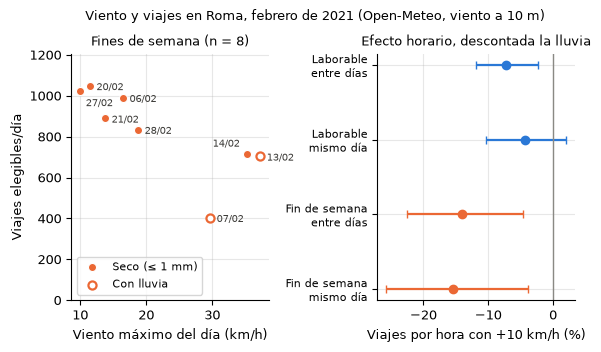

,variable,grupo,n,rho_viajes,rho_con_lluvia,rho_parcial_sin_lluvia,rho_parcial_sin_horas_lluvia,rho_lluvia_parcial_sin_viento,rho_quitando_un_dia_min,rho_quitando_un_dia_max
2,viento_max_kmh,fin_de_semana,8,-0.881,0.382,-0.860,-0.824,-0.291,-0.929,-0.821
5,racha_max_kmh,fin_de_semana,8,-0.807,0.345,-0.778,-0.676,-0.334,-0.883,-0.739


,tipo_dia,modelo,horas,efecto,pct,pct_inf,pct_sup
0,laborable,entre_dias,320,hora con lluvia,-10.1,-19.0,-0.3
1,laborable,entre_dias,320,+10 km/h de viento,-7.2,-11.9,-2.3
2,laborable,dentro_del_dia,320,hora con lluvia,1.4,-8.8,12.9
3,laborable,dentro_del_dia,320,+10 km/h de viento,-4.4,-10.4,2.0
4,fin_de_semana,entre_dias,128,hora con lluvia,-52.7,-60.4,-43.5
5,fin_de_semana,entre_dias,128,+10 km/h de viento,-14.1,-22.6,-4.7
6,fin_de_semana,dentro_del_dia,128,hora con lluvia,-39.6,-58.6,-11.9
7,fin_de_semana,dentro_del_dia,128,+10 km/h de viento,-15.5,-25.7,-3.8


,tipo_dia,horas,dias,viajes,viajes_esperados,cociente
0,fin_de_semana,22,2,1082,1427.5,0.758
1,laborable,5,2,236,290.2,0.813


,fecha,tipo_dia,horas
0,2021-02-08,laborable,4
1,2021-02-10,laborable,1
2,2021-02-13,fin_de_semana,11
3,2021-02-14,fin_de_semana,11


In [7]:
p = PARAMETROS


def spearman_parcial(x, y, z):
    """Spearman de x e y descontando z: correlación de los residuos de sus rangos frente al rango de z."""
    rx, ry, rz = (pd.Series(v).rank().to_numpy(dtype=float) for v in (x, y, z))
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return float(np.corrcoef(ex, ey)[0, 1])


# a) Diario: correlación simple, colinealidad con la lluvia y correlación parcial.
filas = []
for variable in ["viento_max_kmh", "racha_max_kmh"]:
    for grupo, sub in [("todos", serie), ("laborable", serie[serie["tipo_dia"] == "laborable"]),
                       ("fin_de_semana", serie[serie["tipo_dia"] == "fin_de_semana"])]:
        quitar_uno = [spearmanr(sub.drop(i)[variable], sub.drop(i)["viajes"]).statistic for i in sub.index]
        filas.append({
            "variable": variable, "grupo": grupo, "n": len(sub),
            "rho_viajes": spearmanr(sub[variable], sub["viajes"]).statistic,
            "rho_con_lluvia": spearmanr(sub[variable], sub["precipitacion_mm"]).statistic,
            "rho_parcial_sin_lluvia": spearman_parcial(sub[variable], sub["viajes"], sub["precipitacion_mm"]),
            "rho_parcial_sin_horas_lluvia": spearman_parcial(sub[variable], sub["viajes"], sub["horas_lluvia"]),
            "rho_lluvia_parcial_sin_viento": spearman_parcial(sub["precipitacion_mm"], sub["viajes"], sub[variable]),
            "rho_quitando_un_dia_min": min(quitar_uno), "rho_quitando_un_dia_max": max(quitar_uno)})
viento_diario = pd.DataFrame(filas)
viento_diario[viento_diario.columns[3:]] = viento_diario[viento_diario.columns[3:]].astype(float).round(3)
guardar_tabla(viento_diario, "T17_viento_diario")

fds = serie.loc[serie["tipo_dia"] == "fin_de_semana",
                ["fecha", "dia_semana", "viajes", "precipitacion_mm", "horas_lluvia", "viento_max_kmh",
                 "racha_max_kmh", "temp_media_c"]].reset_index(drop=True)
guardar_tabla(fds, "T17_viento_fines_de_semana")

# b) Horario: log(1 + viajes) con efectos fijos, lluvia y viento medio de la hora (por cada 10 km/h).
hv = h.assign(viento_10kmh=h["viento_kmh"] / 10, lluvia_h=h["lluvia"].astype(float),
              tendencia_dias=(h["fecha"] - h["fecha"].min()).dt.days.astype(float))


def efectos_horarios(d, modelo):
    """MCO con efectos fijos de hora (y de día, si modelo == 'dentro_del_dia'). Devuelve el
    efecto en % de viajes de una hora con lluvia y de 10 km/h más de viento, con su intervalo
    al 95 %. El error típico supone horas independientes: el intervalo es orientativo."""
    fijos = [pd.get_dummies(d["hora"].astype(str), prefix="h", dtype=float)]
    otras = ["lluvia_h", "viento_10kmh"]
    if modelo == "dentro_del_dia":
        fijos.append(pd.get_dummies(d["fecha"].dt.strftime("%d"), prefix="d", dtype=float))
    else:
        otras = ["tendencia_dias", "temperatura_c"] + otras
    X = pd.concat(fijos + [d[otras].astype(float)], axis=1)
    A, y = X.to_numpy(), np.log1p(d["viajes"].to_numpy(dtype=float))
    beta = np.linalg.pinv(A) @ y
    residuos = y - A @ beta
    sigma2 = residuos @ residuos / (len(y) - np.linalg.matrix_rank(A))
    ee = np.sqrt(np.diag(sigma2 * np.linalg.pinv(A.T @ A)))
    salida = []
    for nombre, efecto in [("lluvia_h", "hora con lluvia"), ("viento_10kmh", "+10 km/h de viento")]:
        i = list(X.columns).index(nombre)
        salida.append({"efecto": efecto, "pct": 100 * np.expm1(beta[i]),
                       "pct_inf": 100 * np.expm1(beta[i] - 1.96 * ee[i]),
                       "pct_sup": 100 * np.expm1(beta[i] + 1.96 * ee[i])})
    return salida


filas = []
for tipo in ["laborable", "fin_de_semana"]:
    for modelo in ["entre_dias", "dentro_del_dia"]:
        d = hv[hv["tipo_dia"] == tipo]
        for e in efectos_horarios(d, modelo):
            filas.append({"tipo_dia": tipo, "modelo": modelo, "horas": len(d), **e})
viento_horario = pd.DataFrame(filas)
viento_horario[["pct", "pct_inf", "pct_sup"]] = viento_horario[["pct", "pct_inf", "pct_sup"]].round(1)
guardar_tabla(viento_horario, "T17_viento_horario")

# c) Horas secas con viento frente a horas secas en calma de la misma hora y tipo de día (±7 días).
secas_h = hv[~hv["lluvia"]]
calma = secas_h[secas_h["viento_kmh"] < p["umbral_calma_kmh"]]
filas = []
for _, fila in secas_h[secas_h["viento_kmh"] >= p["umbral_viento_kmh"]].iterrows():
    ref = calma[(calma["hora"] == fila["hora"]) & (calma["tipo_dia"] == fila["tipo_dia"])
                & ((calma["fecha"] - fila["fecha"]).abs() <= pd.Timedelta(days=p["ventana_referencia_dias"]))]
    if len(ref):
        filas.append({"fecha": fila["fecha"].strftime("%Y-%m-%d"), "hora": int(fila["hora"]),
                      "tipo_dia": fila["tipo_dia"], "viento_kmh": float(fila["viento_kmh"]),
                      "viajes": int(fila["viajes"]), "viajes_esperados": float(ref["viajes"].mean())})
ventosas = pd.DataFrame(filas)
secas_ventosas = (ventosas.groupby("tipo_dia")
                  .agg(horas=("viajes", "size"), dias=("fecha", "nunique"), viajes=("viajes", "sum"),
                       viajes_esperados=("viajes_esperados", "sum"))
                  .assign(cociente=lambda t: (t["viajes"] / t["viajes_esperados"]).round(3),
                          viajes_esperados=lambda t: t["viajes_esperados"].round(1))
                  .reset_index())
dias_ventosos = ventosas.groupby(["fecha", "tipo_dia"]).size().rename("horas").reset_index()
guardar_tabla(secas_ventosas, "T17_viento_horas_secas")

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(6.5, 3.2), width_ratios=[1, 1],
                                 gridspec_kw={"wspace": 0.55})
seco = fds["precipitacion_mm"] <= 1
eje1.scatter(fds.loc[seco, "viento_max_kmh"], fds.loc[seco, "viajes"], s=34, color=NARANJA, edgecolor="white",
             lw=0.8, label="Seco (≤ 1 mm)", zorder=3)
eje1.scatter(fds.loc[~seco, "viento_max_kmh"], fds.loc[~seco, "viajes"], s=34, facecolor="white",
             edgecolor=NARANJA, lw=1.6, label="Con lluvia", zorder=3)
# Desplazamiento de las etiquetas que se pisan con su vecina.
desplazamiento = {"2021-02-14": (-5, 5, "right"), "2021-02-27": (4, -11, "left")}
for _, fila in fds.iterrows():
    dx, dy, ha = desplazamiento.get(fila["fecha"], (5, -3, "left"))
    eje1.annotate(pd.Timestamp(fila["fecha"]).strftime("%d/%m"), (fila["viento_max_kmh"], fila["viajes"]),
                  xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=7.5, color="#3d3c39")
eje1.set_xlabel("Viento máximo del día (km/h)")
eje1.set_ylabel("Viajes elegibles/día")
eje1.set_ylim(0, fds["viajes"].max() * 1.15)
eje1.legend(loc="lower left")
eje1.set_title("Fines de semana (n = 8)", fontsize=9)
v = viento_horario[viento_horario["efecto"] == "+10 km/h de viento"].reset_index(drop=True)
etiquetas = {("laborable", "entre_dias"): "Laborable\nentre días",
             ("laborable", "dentro_del_dia"): "Laborable\nmismo día",
             ("fin_de_semana", "entre_dias"): "Fin de semana\nentre días",
             ("fin_de_semana", "dentro_del_dia"): "Fin de semana\nmismo día"}
ys = np.arange(len(v))[::-1]
for y, (_, fila) in zip(ys, v.iterrows()):
    eje2.errorbar(fila["pct"], y, xerr=[[fila["pct"] - fila["pct_inf"]], [fila["pct_sup"] - fila["pct"]]],
                  fmt="o", ms=6, color=COLORES_TIPO[fila["tipo_dia"]], capsize=3, lw=1.6)
eje2.axvline(0, color=GRIS, lw=1)
eje2.set_yticks(ys, [etiquetas[(t, m)] for t, m in zip(v["tipo_dia"], v["modelo"])], fontsize=8)
eje2.set_xlabel("Viajes por hora con +10 km/h (%)")
eje2.set_title("Efecto horario, descontada la lluvia", fontsize=9)
fig.suptitle("Viento y viajes en Roma, febrero de 2021 (Open-Meteo, viento a 10 m)", fontsize=9, y=1.02)
guardar_figura(fig, TEMA, "T17_viento")

exportar(FASE, "t17_viento", {"diario": viento_diario, "fines_de_semana": fds, "horario": viento_horario,
                              "horas_secas": secas_ventosas, "dias_ventosos": dias_ventosos,
                              "umbrales": {"viento_kmh": p["umbral_viento_kmh"], "calma_kmh": p["umbral_calma_kmh"]}})
display(viento_diario[viento_diario["grupo"] == "fin_de_semana"])
display(viento_horario)
display(secas_ventosas)
display(dias_ventosos)


**Conclusiones.**

- **El viento no es un reflejo de la lluvia.** En los 8 días de fin de semana el viento máximo y la lluvia apenas van juntos (Spearman de 0,38). Descontando la lluvia, la correlación del viento con los viajes sigue en −0,86 (−0,82 descontando las horas de lluvia). Quitando cualquier día queda entre −0,82 y −0,93. Al revés, la lluvia descontando el viento baja a −0,29. Con la racha máxima sale lo mismo, algo más débil.
- **Por horas se confirma con los dos efectos a la vez.** En fin de semana, 10 km/h más de viento medio en la hora quitan un 14 % de los viajes entre días (IC 95 % de −23 a −5 %) y un 16 % dentro del mismo día (−26 a −4 %). La lluvia, en el mismo modelo, quita entre un 40 y un 53 % en las horas en que llueve. En laborables el viento quita un 7 % entre días y un 4 % dentro del día, sin diferencia clara con cero: el viaje al trabajo se hace igual.
- **Las horas secas con viento lo muestran sin modelo.** En fin de semana, las 22 horas secas con al menos 20 km/h tuvieron el 76 % de los viajes de las horas secas en calma de la misma hora. Todas son del 13 y el 14/02.
- **El límite es que la prueba descansa en un episodio.** El fin de semana del 13–14/02 fue frío y con rachas de 67–70 km/h. El 14/02 no llovió y tuvo 717 viajes, frente a 889–1 048 de los fines de semana secos y en calma. El modelo horario descuenta la temperatura y el efecto se mantiene, pero es un solo episodio en un solo mes.
- **Conclusión final.** El viento fuerte reduce la demanda de ocio del fin de semana por sí mismo, con un efecto menor que el de la lluvia pero claro, y casi no afecta a los laborables. No se mete el viento en el simulador: con un episodio no se puede ajustar, y el dimensionado se hace con días normales. El 13 y el 14/02 se tratan como el 07/02: se quedan en los datos, se marcan como días de tiempo adverso y no se usan como días de diseño. La semana reservada fue seca y con menos viento (13,5 km/h de máximo medio frente a 18,3 en el ajuste), lo que refuerza que la validación es más exigente.

## 7. Tabla de indicadores

**Qué queremos ver.** Los indicadores de lluvia, temperatura y demanda por periodo en una tabla.

**Por qué importa.** Es la tabla que citan `docs/conclusiones_eda.md` y la memoria.

In [8]:
resumen = tabla_resumen({
    "fichero_meteorologia": FICHERO.name,
    "dias": len(serie),
    "dias_con_lluvia_mayor_1mm": int((serie["precipitacion_mm"] > 1).sum()),
    "lluvia_total_ajuste_mm": serie.loc[en_ajuste, "precipitacion_mm"].sum(),
    "lluvia_total_reservada_mm": serie.loc[~en_ajuste, "precipitacion_mm"].sum(),
    "dias_lluvia_mayor_1mm_ajuste": int((en_ajuste & (serie["precipitacion_mm"] > 1)).sum()),
    "dias_lluvia_mayor_1mm_reservada": int((~en_ajuste & (serie["precipitacion_mm"] > 1)).sum()),
    "temperatura_media_ajuste_c": serie.loc[en_ajuste, "temp_media_c"].mean(),
    "temperatura_media_reservada_c": serie.loc[~en_ajuste, "temp_media_c"].mean(),
    "viajes_dia_media_ajuste": serie.loc[en_ajuste, "viajes"].mean(),
    "viajes_dia_media_reservada": serie.loc[~en_ajuste, "viajes"].mean(),
    "dias_anomalos": int(serie["anomalo"].sum()),
    "viento_max_medio_ajuste_kmh": serie.loc[en_ajuste, "viento_max_kmh"].mean(),
    "viento_max_medio_reservada_kmh": serie.loc[~en_ajuste, "viento_max_kmh"].mean(),
    "racha_max_reservada_kmh": serie.loc[~en_ajuste, "racha_max_kmh"].max(),
    "celda_meteo_lat": datos_meteo["latitude"],
    "celda_meteo_lon": datos_meteo["longitude"],
    "distancia_celda_meteo_km": haversine_m(PARAMETROS["latitud"], PARAMETROS["longitud"],
                                            datos_meteo["latitude"], datos_meteo["longitude"]) / 1000,
})
guardar_tabla(resumen, "T17_resumen")
exportar(FASE, "t17_resumen", resumen)
display(resumen)

,indicador,valor
0,fichero_meteorologia,open-meteo_roma_2021-02_2026-11-18.json
1,dias,28
2,dias_con_lluvia_mayor_1mm,6
3,lluvia_total_ajuste_mm,75.7
4,lluvia_total_reservada_mm,0.0
5,dias_lluvia_mayor_1mm_ajuste,6
6,dias_lluvia_mayor_1mm_reservada,0
7,temperatura_media_ajuste_c,9.3238
8,temperatura_media_reservada_c,10.9429
9,viajes_dia_media_ajuste,795.7143


## Decisiones

| Decisión | Valor |
|---|---|
| ¿Excluir algún día? | No: el 07/02 (lluvia) y el 13–14/02 (viento fuerte y frío) son días reales de tiempo adverso; se marcan y no se usan como días de diseño |
| ¿Entra el viento en el simulador? | No: reduce la demanda del fin de semana por sí mismo (−14 % por cada 10 km/h), pero la prueba es un solo episodio |
| ¿Es comparable la semana reservada? | Con cautela: +18,2 % de viajes, sin lluvia, más cálida y con menos viento; la validación es más exigente |
| Restricciones por COVID | Sin afirmación: no hay fuente oficial leída |

El detalle de cada decisión está en `docs/conclusiones_eda.md`.